# Fraud Detection Case
**Carlos Almeida** · Data Scientist - Fluent English

**Goal:** use the 2025 transaction history (labelled) to build a model that classifies the January 2026 transactions as fraud or not fraud.

**Plan**
1. Load and check the data
2. Exploratory analysis: what separates fraud from normal transactions?
3. Feature selection
4. Model and evaluation *(developed with AI assistance)*
5. Score January 2026 and export the results *(developed with AI assistance)*
6. Conclusions

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("ATF-DataScience") if Path("ATF-DataScience").exists() else Path(".")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
ORANGE, NAVY = "#e8590c", "#1f2a44"

## 1. Loading and checking the data

In [2]:
hist = pd.read_csv(DATA_DIR / "transacoes_historico_2025.csv", parse_dates=["datahora_transacao"])
jan = pd.read_csv(DATA_DIR / "transacoes_jan2026.csv", parse_dates=["datahora_transacao"])

print("History 2025:", hist.shape)
print("January 2026:", jan.shape)
hist.head()

History 2025: (523525, 15)
January 2026: (44451, 14)


,datahora_transacao,nome_estabelecimento,tipo_estabelecimento,valor_transacao,nome_cliente,cidade,flag_fraude,device_type,is_new_device,temperatura_celsius,codigo_postal,score_interno,turno,valor_categoria,cidade_regiao
0,2025-01-01 00:00:00,Pharmacy Z,Pharmacy,9.12,Cliente_16621,Recife,False,desktop,False,31.5,72519-282,562,madrugada,baixo,Nordeste
1,2025-01-01 00:01:00,Supermarket A,Supermarket,37.74,Cliente_12596,Recife,False,mobile,False,28.1,43549-179,461,madrugada,medio,Nordeste
2,2025-01-01 00:02:00,Restaurant Y,Food & Beverage,30.94,Cliente_10474,Salvador,False,mobile,True,29.1,68582-277,577,madrugada,medio,Nordeste
3,2025-01-01 00:03:00,Gas Station,Fuel,41.72,Cliente_20661,Salvador,False,mobile,True,28.6,21497-208,666,madrugada,medio,Nordeste
4,2025-01-01 00:04:00,Online Shop 2,E-commerce,13.85,Cliente_4018,Rio de Janeiro,False,mobile,False,30.2,50814-648,892,madrugada,baixo,Sudeste


In [3]:
hist.info()

<class 'pandas.DataFrame'>
RangeIndex: 523525 entries, 0 to 523524
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   datahora_transacao    523525 non-null  datetime64[us]
 1   nome_estabelecimento  523525 non-null  str           
 2   tipo_estabelecimento  523525 non-null  str           
 3   valor_transacao       523525 non-null  float64       
 4   nome_cliente          523525 non-null  str           
 5   cidade                523525 non-null  str           
 6   flag_fraude           523525 non-null  bool          
 7   device_type           523525 non-null  str           
 8   is_new_device         523525 non-null  bool          
 9   temperatura_celsius   523525 non-null  float64       
 10  codigo_postal         523525 non-null  str           
 11  score_interno         523525 non-null  int64         
 12  turno                 523525 non-null  str           
 13  valor_cate

In [4]:
print("Missing values (history):", hist.isna().sum().sum())
print("Missing values (january):", jan.isna().sum().sum())
print("Duplicated rows (history):", hist.duplicated().sum())
print("Duplicated rows (january):", jan.duplicated().sum())

Missing values (history): 0
Missing values (january): 0


Duplicated rows (history): 0
Duplicated rows (january): 0


The data is clean: no missing values and no duplicates. January 2026 has the same columns as the history, except `flag_fraude`, which is what I need to predict.

## 2. Exploratory analysis

In [5]:
hist["fraud"] = hist["flag_fraude"].astype(int)
hist["hour"] = hist["datahora_transacao"].dt.hour
hist["month"] = hist["datahora_transacao"].dt.month
jan["hour"] = jan["datahora_transacao"].dt.hour

hist["flag_fraude"].value_counts(normalize=True)

flag_fraude
False    0.960871
True     0.039129
Name: proportion, dtype: float64

Only **3.9%** of the transactions are fraud. The classes are very unbalanced, so accuracy would be a bad metric: a model that always says "not fraud" would be 96% accurate and useless.

From here on I look at the **fraud rate** (share of transactions that are fraud) in each group.

### 2.1 Time of the transaction

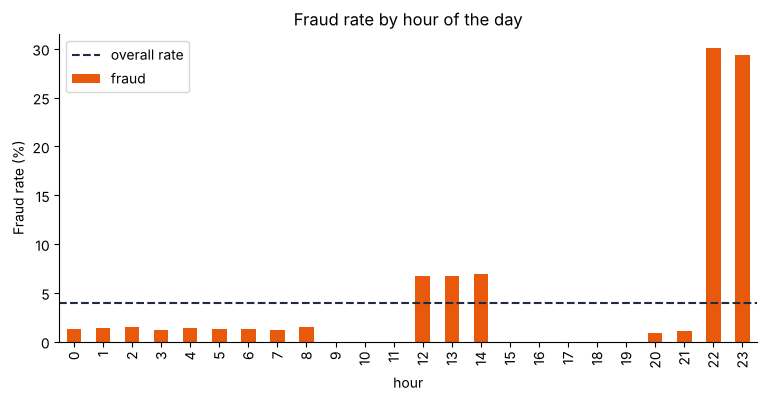

In [6]:
fraud_by_hour = hist.groupby("hour")["fraud"].mean() * 100

fraud_by_hour.plot(kind="bar", color=ORANGE)
plt.axhline(hist["fraud"].mean() * 100, color=NAVY, linestyle="--", label="overall rate")
plt.title("Fraud rate by hour of the day")
plt.ylabel("Fraud rate (%)")
plt.legend()
plt.show()

In [7]:
hist.groupby("turno")["fraud"].mean().sort_values(ascending=False)

turno
noite        0.102410
tarde        0.033995
madrugada    0.013481
manha        0.006637
Name: fraud, dtype: float64

The hour is the clearest pattern I found. At **22h and 23h about 30%** of transactions are fraud, there is a smaller peak at lunch time (12h–14h) and some hours have almost no fraud. The `turno` column (shift) shows the same thing, but in less detail, because it is just the hour grouped into 4 blocks.

### 2.2 Device

In [8]:
print(hist.groupby("is_new_device")["fraud"].mean())
print()
print(hist.groupby("device_type")["fraud"].mean())

is_new_device
False    0.021264
True     0.128990
Name: fraud, dtype: float64

device_type
desktop    0.028263
mobile     0.049152
tablet     0.020622
Name: fraud, dtype: float64


A transaction from a **new device** has a fraud rate of about 12.9%, against 2.1% for a known device (about 6 times higher). Mobile is riskier than desktop and tablet.

### 2.3 Merchant and city

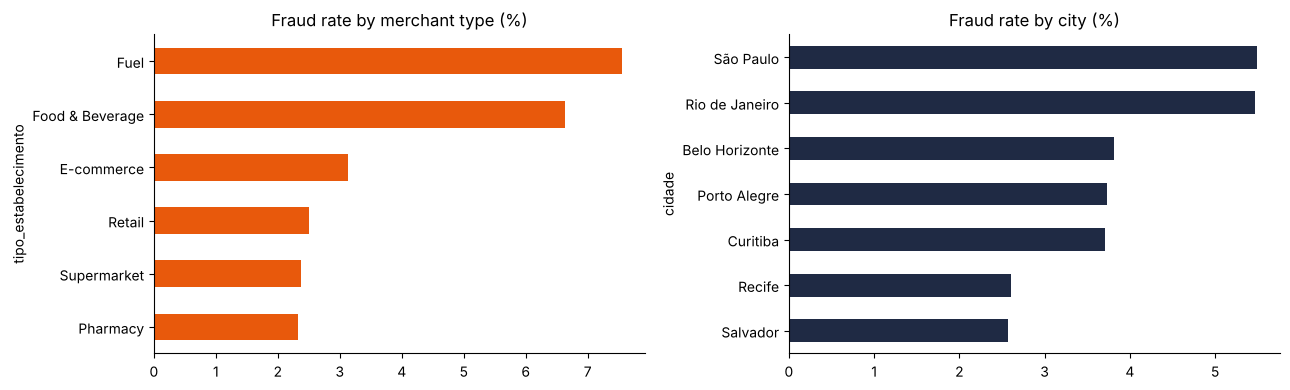

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

(hist.groupby("tipo_estabelecimento")["fraud"].mean() * 100).sort_values().plot(kind="barh", ax=axes[0], color=ORANGE)
axes[0].set_title("Fraud rate by merchant type (%)")

(hist.groupby("cidade")["fraud"].mean() * 100).sort_values().plot(kind="barh", ax=axes[1], color=NAVY)
axes[1].set_title("Fraud rate by city (%)")

plt.tight_layout()
plt.show()

In [10]:
hist.groupby(["tipo_estabelecimento", "nome_estabelecimento"])["fraud"].mean()

tipo_estabelecimento  nome_estabelecimento
E-commerce            Online Shop 1           0.031086
                      Online Shop 2           0.031408
Food & Beverage       Restaurant X            0.067040
                      Restaurant Y            0.065547
Fuel                  Gas Station             0.075475
Pharmacy              Pharmacy Z              0.023255
Retail                Clothing Store          0.024943
                      Electronics Store       0.025187
Supermarket           Supermarket A           0.024089
                      Supermarket B           0.023400
Name: fraud, dtype: float64

**Fuel** and **Food & Beverage** have the highest fraud rates. Merchants of the same type behave alike (for example, Restaurant X and Restaurant Y). Among the cities, **Rio de Janeiro** and **São Paulo** have the highest rates and Recife and Salvador the lowest.

### 2.4 Transaction value

In [11]:
hist.groupby("flag_fraude")["valor_transacao"].describe()

,count,mean,std,min,25%,50%,75%,max
flag_fraude,,,,,,,,
False,503040.0,44.496455,75.786833,0.50,14.03,25.11,45.43,722.90
True,20485.0,30.861887,16.619127,4.41,19.41,27.21,37.96,218.83


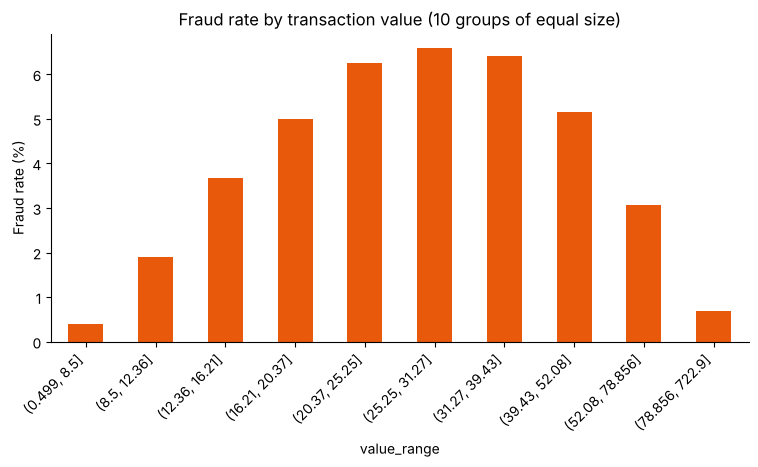

In [12]:
hist["value_range"] = pd.qcut(hist["valor_transacao"], 10)

(hist.groupby("value_range", observed=True)["fraud"].mean() * 100).plot(kind="bar", color=ORANGE)
plt.title("Fraud rate by transaction value (10 groups of equal size)")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=45, ha="right")
plt.show()

Fraud is concentrated in **medium values** (roughly 15 to 50). Very small and very large transactions are rarely fraud. This is not a straight line, so a "bigger value = more risk" rule would not work.

### 2.5 Variables that look like noise

In [13]:
hist.groupby("flag_fraude")[["score_interno", "temperatura_celsius"]].mean()

,score_interno,temperatura_celsius
flag_fraude,,
False,500.415701,24.017655
True,499.338199,23.699297


In [14]:
hist["score_range"] = pd.cut(hist["score_interno"], 5)
hist["weekday"] = hist["datahora_transacao"].dt.day_name()

print(hist.groupby("score_range", observed=True)["fraud"].mean().round(4))
print()
print(hist.groupby("weekday")["fraud"].mean().round(4))
print()
print("Unique postal codes:", hist["codigo_postal"].nunique(), "of", len(hist), "rows")

score_range
(-1.0, 200.0]      0.0395
(200.0, 400.0]     0.0391
(400.0, 600.0]     0.0390
(600.0, 800.0]     0.0393
(800.0, 1000.0]    0.0388
Name: fraud, dtype: float64

weekday
Friday       0.0376
Monday       0.0405
Saturday     0.0385
Sunday       0.0395
Thursday     0.0386
Tuesday      0.0391
Wednesday    0.0401
Name: fraud, dtype: float64

Unique postal codes: 521905 of 523525 rows


In [15]:
frauds_per_customer = hist.groupby("nome_cliente")["fraud"].sum()
frauds_per_customer.value_counts().sort_index()

fraud
0    12002
1     9386
2     3636
3      973
4      180
5       35
6        1
7        1
Name: count, dtype: int64

Some columns do not help to separate fraud:
* `score_interno` and `temperatura_celsius` have the same average for fraud and non-fraud, and the fraud rate is flat across score ranges.
* The **day of the week** does not change the fraud rate.
* `codigo_postal` is almost unique for every transaction, so it cannot be grouped.
* Frauds are spread across customers (most have 0, 1 or 2 frauds out of about 20 transactions), so no group of customers stands out.

### 2.6 Fraud over the months

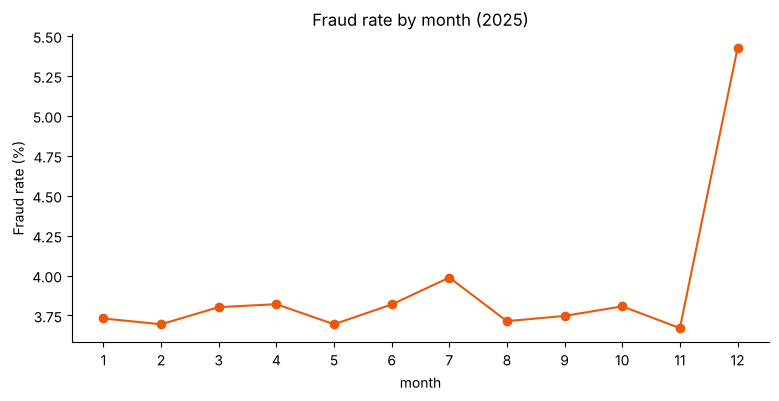

In [16]:
(hist.groupby("month")["fraud"].mean() * 100).plot(marker="o", color=ORANGE)
plt.title("Fraud rate by month (2025)")
plt.ylabel("Fraud rate (%)")
plt.xticks(range(1, 13))
plt.show()

In [17]:
hist["period"] = hist["month"].map(lambda m: "December" if m == 12 else "Jan-Nov")
ecommerce_night = hist[(hist["tipo_estabelecimento"] == "E-commerce") & (hist["hour"] >= 20)]

ecommerce_night.groupby("period")["fraud"].mean()

period
December    0.600000
Jan-Nov     0.147357
Name: fraud, dtype: float64

The fraud rate is stable at about 3.7% from January to November and goes up to 5.4% in December. When I looked for the reason, almost all of the increase comes from **E-commerce at night (20h–23h)**, which went from about 15% to 60% fraud. All other groups stayed the same.

This could be a seasonal effect (end-of-year shopping) or a new type of attack. With only one month of data I cannot be sure, so I note it as a point to monitor and keep December in the training data.

## 3. Feature selection

Based on the analysis, I keep the variables that show a clear difference in fraud rate:

| Feature | Reason |
|---|---|
| hour (from `datahora_transacao`) | strongest pattern |
| `is_new_device` | new device ≈ 6x more fraud |
| `device_type` | mobile is riskier |
| `nome_estabelecimento` | merchant type matters (and it already contains the type) |
| `cidade` | Rio and São Paulo are riskier |
| `valor_transacao` | fraud concentrated in medium values |

And I drop:
* **Repeated information:** `turno` (comes from the hour), `tipo_estabelecimento` (comes from the merchant name), `cidade_regiao` (comes from the city), `valor_categoria` (comes from the value).
* **No signal:** `score_interno`, `temperatura_celsius`, `codigo_postal`, `nome_cliente` and weekday.

In [18]:
CAT_COLS = ["nome_estabelecimento", "cidade", "device_type"]


def build_features(df):
    X = pd.get_dummies(df[CAT_COLS]).astype(int)
    X["is_new_device"] = df["is_new_device"].astype(int)
    X["hour"] = df["hour"]
    X["valor_transacao"] = df["valor_transacao"]
    return X


X = build_features(hist)
y = hist["fraud"]
print("Features after one-hot encoding:", X.shape[1])

Features after one-hot encoding: 23


## 4. Model and evaluation *(developed with AI assistance)*

> The modelling steps below were built with the help of an AI assistant. I reviewed each step and the reasoning behind it.

**How I test the model.** The model will be used on future data, so I train it on **January to November** and test it on **December**, a month it has never seen. A random split would mix future information into the training data.

**Models.**
* **Decision tree:** a set of yes/no rules (for example "hour ≥ 22 and new device → high risk"). Easy to read.
* **Random forest:** many decision trees, each trained on a random sample of the data; the final answer is the average of their votes. Usually more accurate and stable than a single tree.

**Metrics.**
* **PR-AUC (average precision):** how well the model ranks frauds at the top. A model that guesses at random scores about the fraud rate (~0.05 in December).
* **Precision:** of the transactions the model flags, how many are really fraud.
* **Recall:** of all frauds, how many the model catches.

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score

train = hist["month"] <= 11
test = hist["month"] == 12

tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=42)
tree.fit(X[train], y[train])
tree_prob = tree.predict_proba(X[test])[:, 1]

forest = RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42)
forest.fit(X[train], y[train])
forest_prob = forest.predict_proba(X[test])[:, 1]

results = pd.DataFrame({
    "PR-AUC": [y[test].mean(), average_precision_score(y[test], tree_prob), average_precision_score(y[test], forest_prob)],
    "ROC-AUC": [0.5, roc_auc_score(y[test], tree_prob), roc_auc_score(y[test], forest_prob)],
}, index=["Random guess", "Decision tree", "Random forest"])
results.round(3)

,PR-AUC,ROC-AUC
Random guess,0.054,0.500
Decision tree,0.563,0.888
Random forest,0.611,0.923


### 4.1 Choosing the cut-off (threshold)
The model gives a **probability** of fraud. I need a cut-off to turn it into "fraud / not fraud". A low cut-off catches more fraud but also blocks more good customers. The table shows this trade-off on December.

In [20]:
rows = []
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    flagged = forest_prob >= threshold
    rows.append({
        "threshold": threshold,
        "precision": precision_score(y[test], flagged),
        "recall": recall_score(y[test], flagged),
        "f1": f1_score(y[test], flagged),
        "flagged_%": flagged.mean() * 100,
    })

threshold_table = pd.DataFrame(rows).round(3)
THRESHOLD = threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"]
print("Chosen threshold (best balance between precision and recall, F1):", THRESHOLD)
threshold_table

Chosen threshold (best balance between precision and recall, F1): 0.2


,threshold,precision,recall,f1,flagged_%
0,0.1,0.430,0.800,0.559,10.083
1,0.2,0.533,0.702,0.606,7.138
2,0.3,0.677,0.507,0.580,4.063
3,0.4,0.762,0.418,0.540,2.974
4,0.5,0.784,0.348,0.482,2.407


### 4.2 Which variables matter most?

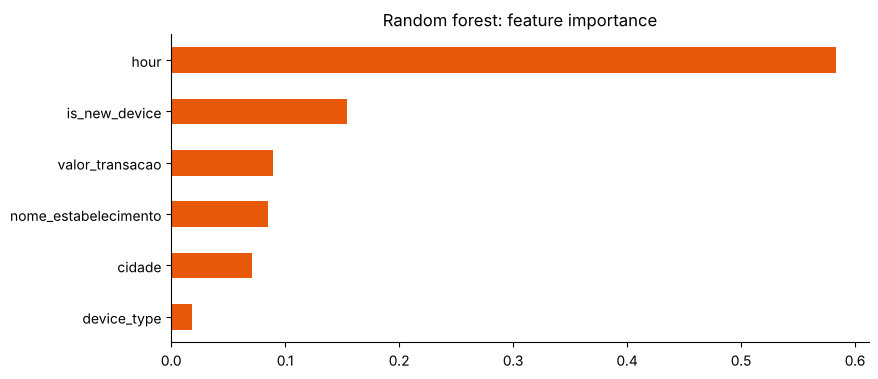

In [21]:
def original_column(name):
    for col in CAT_COLS:
        if name.startswith(col + "_"):
            return col
    return name


importance = pd.Series(forest.feature_importances_, index=X.columns)
importance = importance.groupby(original_column).sum().sort_values()

importance.plot(kind="barh", color=ORANGE)
plt.title("Random forest: feature importance")
plt.show()

## 5. Scoring January 2026 *(developed with AI assistance)*
The final random forest is trained on **all of 2025** (including December) and applied to January 2026 with the chosen threshold.

In [22]:
final_model = RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20, n_jobs=-1, random_state=42)
final_model.fit(X, y)

X_jan = build_features(jan).reindex(columns=X.columns, fill_value=0)
jan["fraud_probability"] = final_model.predict_proba(X_jan)[:, 1]
jan["flag_fraude"] = jan["fraud_probability"] >= THRESHOLD

print(f"Transactions scored: {len(jan):,}")
print(f"Flagged as fraud:    {jan['flag_fraude'].sum():,} ({jan['flag_fraude'].mean():.1%})")

Transactions scored: 44,451
Flagged as fraud:    3,182 (7.2%)


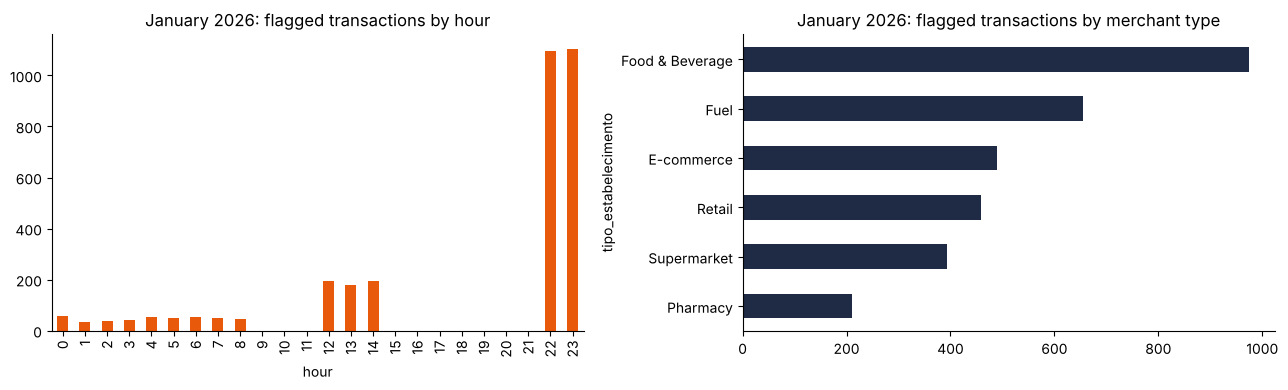

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

jan.groupby("hour")["flag_fraude"].sum().plot(kind="bar", ax=axes[0], color=ORANGE)
axes[0].set_title("January 2026: flagged transactions by hour")

jan.groupby("tipo_estabelecimento")["flag_fraude"].sum().sort_values().plot(kind="barh", ax=axes[1], color=NAVY)
axes[1].set_title("January 2026: flagged transactions by merchant type")

plt.tight_layout()
plt.show()

In [24]:
jan.drop(columns="hour").to_csv(OUT_DIR / "transacoes_jan2026_classified.csv", index=False)
print("Saved:", OUT_DIR / "transacoes_jan2026_classified.csv")

Saved: outputs/transacoes_jan2026_classified.csv


### 5.1 Formatted Excel version
A styled copy of the January results for reading: English headers in a fixed order, values in R$, probability in %, a green-yellow-red colour scale on the internal score and flagged transactions highlighted. The CSV above keeps the raw numbers.

In [25]:
from openpyxl import load_workbook
from openpyxl.comments import Comment
from openpyxl.formatting.rule import ColorScaleRule, FormulaRule
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter

COLUMNS = {
    "datahora_transacao": "Transaction Date & Time",
    "cidade": "City",
    "codigo_postal": "Postal Code",
    "cidade_regiao": "City Region",
    "temperatura_celsius": "Temperature (°C)",
    "turno": "Shift",
    "device_type": "Device Type",
    "is_new_device": "New Device",
    "tipo_estabelecimento": "Merchant Type",
    "nome_estabelecimento": "Merchant Name",
    "nome_cliente": "Customer Name",
    "valor_transacao": "Transaction Value",
    "score_interno": "Internal Score",
    "valor_categoria": "Value Category",
    "fraud_probability": "Fraud Probability",
    "flag_fraude": "Fraud Flag",
}
TRANSLATIONS = {
    "cidade_regiao": {"Sudeste": "Southeast", "Sul": "South", "Nordeste": "Northeast"},
    "turno": {"madrugada": "Overnight", "manha": "Morning", "tarde": "Afternoon", "noite": "Night"},
    "device_type": {"mobile": "Mobile", "desktop": "Desktop", "tablet": "Tablet"},
    "valor_categoria": {"baixo": "Low", "medio": "Medium", "alto": "High"},
    "is_new_device": {True: "Yes", False: "No"},
    "flag_fraude": {True: "Yes", False: "No"},
}
LEFT = ["City", "City Region", "Device Type", "Merchant Type", "Merchant Name", "Customer Name"]
RIGHT = ["Transaction Value", "Internal Score", "Fraud Probability", "Temperature (°C)"]
FORMATS = {"Transaction Date & Time": "yyyy-mm-dd hh:mm", "Transaction Value": '"R$" #,##0.00',
           "Fraud Probability": "0.0%", "Temperature (°C)": "0.0", "Internal Score": "0"}

table = jan[list(COLUMNS)].copy()
for col, mapping in TRANSLATIONS.items():
    table[col] = table[col].map(mapping)
table = table.rename(columns=COLUMNS)

xlsx_path = OUT_DIR / "transacoes_jan2026_classified.xlsx"
table.to_excel(xlsx_path, index=False, sheet_name="January 2026")

wb = load_workbook(xlsx_path)
ws = wb.active
last_row = ws.max_row
last_col = get_column_letter(ws.max_column)
body_font = Font(name="Arial", size=10)

for idx, header in enumerate(table.columns, start=1):
    letter = get_column_letter(idx)
    horizontal = "left" if header in LEFT else "right" if header in RIGHT else "center"
    align = Alignment(horizontal=horizontal, vertical="center")
    number_format = FORMATS.get(header)
    for (cell,) in ws.iter_rows(min_row=2, min_col=idx, max_col=idx):
        cell.font = body_font
        cell.alignment = align
        if number_format:
            cell.number_format = number_format

    longest = max(len(header), table[header].astype(str).str.len().max())
    ws.column_dimensions[letter].width = min(longest + 4, 28) if header != "Transaction Date & Time" else 19

    head = ws.cell(row=1, column=idx)
    head.font = Font(name="Arial", size=10, bold=True, color="FFFFFF")
    head.fill = PatternFill("solid", start_color="1F2A44")
    head.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

ws.row_dimensions[1].height = 30
ws.freeze_panes = "A2"
ws.auto_filter.ref = f"A1:{last_col}{last_row}"

# Flagged rows first, then light banding on the remaining rows
ws.conditional_formatting.add(f"A2:{last_col}{last_row}",
    FormulaRule(formula=['$P2="Yes"'], fill=PatternFill("solid", start_color="FDE2D6", end_color="FDE2D6"), stopIfTrue=True))
ws.conditional_formatting.add(f"A2:{last_col}{last_row}",
    FormulaRule(formula=["MOD(ROW(),2)=0"], fill=PatternFill("solid", start_color="F4F6FA", end_color="F4F6FA")))
ws.conditional_formatting.add(f"M2:M{last_row}",
    ColorScaleRule(start_type="num", start_value=0, start_color="F8696B",
                   mid_type="num", mid_value=500, mid_color="FFEB84",
                   end_type="num", end_value=1000, end_color="63BE7B"))

ws["M1"].comment = Comment("Colour scale: 0 = red, 500 = yellow, 1000 = green. "
                           "Note: this score showed no relation with fraud in 2025 and is not used by the model.", "Carlos")
ws["O1"].comment = Comment(f"Random forest probability. Transactions at or above {THRESHOLD:.0%} are flagged as fraud.", "Carlos")

wb.save(xlsx_path)
wb.close()
print("Saved:", xlsx_path)

Saved: outputs/transacoes_jan2026_classified.xlsx


## 6. Conclusions

In [26]:
december_flags = forest_prob >= THRESHOLD
print(f"December test - PR-AUC:    {average_precision_score(y[test], forest_prob):.2f}")
print(f"December test - precision: {precision_score(y[test], december_flags):.0%}")
print(f"December test - recall:    {recall_score(y[test], december_flags):.0%}")
print(f"January 2026 - flagged:    {jan['flag_fraude'].sum():,} of {len(jan):,} ({jan['flag_fraude'].mean():.1%})")

December test - PR-AUC:    0.61
December test - precision: 53%
December test - recall:    70%
January 2026 - flagged:    3,182 of 44,451 (7.2%)


**What I found**
* Fraud is concentrated, not random. The strongest signals are the **hour** (22h–23h ≈ 30% fraud), a **new device** (≈ 6x more fraud), the **merchant** (Fuel and Food & Beverage), the **city** (Rio de Janeiro and São Paulo) and **medium transaction values**.
* `score_interno`, temperature, postal code, weekday and customer history did not help, so I left them out.

**Model**
* A **random forest** with 6 variables, trained on January–November and tested on December (a month it had not seen): PR-AUC **0.61**, against 0.56 for a single decision tree and 0.05 for a random guess.
* With a cut-off of **0.2**, it caught **70%** of December frauds, and **53%** of the transactions it flagged were really fraud.

**January 2026**
* **3,182 of 44,451** transactions (7.2%) are classified as fraud. The results are in `outputs/transacoes_jan2026_classified.csv` (raw numbers) and in a formatted Excel version.

**Points of attention and next steps**
1. **December change:** E-commerce at night went from ~15% to 60% fraud in December. With only one month, I cannot say if this is seasonal or a new attack. I would check it with the fraud team and retrain the model when January labels are confirmed.
2. **Cut-off by business cost:** I chose the cut-off by the F1 score, because the cost of a missed fraud versus a blocked customer was not given. With that information, the cut-off can be adjusted.
3. **Softer action for medium risk:** instead of blocking every flagged transaction, ask for extra authentication (for example a code by SMS) when the probability is medium, to protect good customers.
4. **Retrain every month** and follow the fraud rate by hour and merchant type, to notice changes early.